In [ ]:
#Verwendete Literatur: 
    #"Hands-On Machine Learning with Scikit-Learn, Keras & TensorFlow: Concepts, Tools, an Techniques to build Intelligent Systems" von Aurelien Géron, 2. Edition, updated for TensorFlow 2.
    #"Praktische Statistik für Data Scientists: 50+ essenzielle Konzepte mit R und Python" von Peter Bruce, Andrew Bruce & Peter Gedeck. Übersetzung von Marcus Fraaß.

Teilaufgabe 3a) Datenanalyse- und Aufbereitung

"""Durchführung einer Datenbereinigung und einer explorativen Datenanalyse, um die
wichtigen Merkmale herauszufiltern."""

In [135]:
#Zunächst wird eine Funktion (load_house_data) erstellt, mit der die zu analysierenden Daten abgerufen kann.

import os             
import urllib         
import pandas as pd   

HOUSES_PATH = os.path.join("datasets", "houses")
HOUSES_URL = "datasets/houses"

#Funktion zum Abrufen der Daten.
def load_house_data(houses_path=HOUSES_PATH):
    csv_path = os.path.join(houses_path, "housedata.csv")
    return pd.read_csv(csv_path)

In [136]:
#Übersicht über Merkmalen, die sich im Datensatz befinden
houses = load_house_data()
houses.head()

,LotArea,OverallQual,OverallCond,TotalBsmtSF,FullBath,HalfBath,BedroomAbvGr,TotRmsAbvGrd,Fireplaces,GarageArea,AboveMedianPrice
0,8450,7,5,856,2,1,3,8,0,548,1
1,9600,6,8,1262,2,0,3,6,1,460,1
2,11250,7,5,920,2,1,3,6,1,608,1
3,9550,7,5,756,1,0,3,7,1,642,0
4,14260,8,5,1145,2,1,4,9,1,836,1


In [137]:
#Datenbereinigung
    #Hier wird es darum gehen, die fehlenden Daten zu analysieren, eventuell die Ausreißer zu entfernen.
        #Strukturanalyse des Datensatzes
        houses.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   LotArea           1460 non-null   int64
 1   OverallQual       1460 non-null   int64
 2   OverallCond       1460 non-null   int64
 3   TotalBsmtSF       1460 non-null   int64
 4   FullBath          1460 non-null   int64
 5   HalfBath          1460 non-null   int64
 6   BedroomAbvGr      1460 non-null   int64
 7   TotRmsAbvGrd      1460 non-null   int64
 8   Fireplaces        1460 non-null   int64
 9   GarageArea        1460 non-null   int64
 10  AboveMedianPrice  1460 non-null   int64
dtypes: int64(11)
memory usage: 125.6 KB


In [ ]:
    #Beschreibung der resultierenden Daten
    """Der Datensatz enthält 1460 Instanzen und 11 Spalten oder Variablen.
       Es gibt keine fehlenden Merkmale.
       Alle Werte haben einen einzigen Typ : Integer.
       Hierbei handelt es sich um Merkmale, die beim Kauf eines Hauses berücksichtigt werden sollten. 
       Das Ziel ist es, die Daten zu bereinigen und zu analysieren, um die wichtigsten Merkmale zu bestimmen.
    """

In [138]:
    #Untersuchung einzelner numerischer Variablen: Mit dem Ziel, eine Schätzung abzugeben, wo sich die Mehrheit der Daten konzentriert (d. h. ihre zentrale Tendenz).
    houses.describe()

,LotArea,OverallQual,OverallCond,TotalBsmtSF,FullBath,HalfBath,BedroomAbvGr,TotRmsAbvGrd,Fireplaces,GarageArea,AboveMedianPrice
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,10516.828082,6.099315,5.575342,1057.429452,1.565068,0.382877,2.866438,6.517808,0.613014,472.980137,0.498630
std,9981.264932,1.382997,1.112799,438.705324,0.550916,0.502885,0.815778,1.625393,0.644666,213.804841,0.500169
min,1300.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000
25%,7553.500000,5.000000,5.000000,795.750000,1.000000,0.000000,2.000000,5.000000,0.000000,334.500000,0.000000
50%,9478.500000,6.000000,5.000000,991.500000,2.000000,0.000000,3.000000,6.000000,1.000000,480.000000,0.000000
75%,11601.500000,7.000000,6.000000,1298.250000,2.000000,1.000000,3.000000,7.000000,1.000000,576.000000,1.000000
max,215245.000000,10.000000,9.000000,6110.000000,3.000000,2.000000,8.000000,14.000000,3.000000,1418.000000,1.000000


In [13]:
    #Beschriebung
        """count: wird für die Gesamtzahl der Beobachtungen der betreffenden Variable gesetzt.
           mean: steht für den Durchschnitt.
           std: zeigt die Standardabweichung, die angibt, wie weit die Werte auseinander liegen.
           Die Zeilen 25%, 50%(median) und 75% zeigen die entsprechenden Perzentile: Ein Perzentil gibt den Wert an, 
           unter den ein bestimmter Prozentsatz der Beobachtungen in einer Gruppe von Beobachtungen fällt.
           min und max sind selbst erklärend.
        """

'50% représente la médiane'

In [141]:
    #Hier wird versucht, Streumaße zu bewerten, Um mögliche Ausreißer zu erkennen und zu entfernen.
        #Standardabstand. z.B. Variable "LotArea"
        houses['LotArea'].std()

9981.26493237915

In [142]:
        #Interquartilsabstand
        houses['LotArea'].quantile(0.75) - houses['LotArea'].quantile(0.25)

4048.0

In [ ]:
        #Beschreibung
            """Hier fällt auf, dass der Wert von Standardabweichung doppelt so hoch ist wie der von Interquartilabstand. 
               Dies liegt daran, dass die Standardabweichung gegenüber Ausreißern empfindlich ist.
            """

<AxesSubplot:>

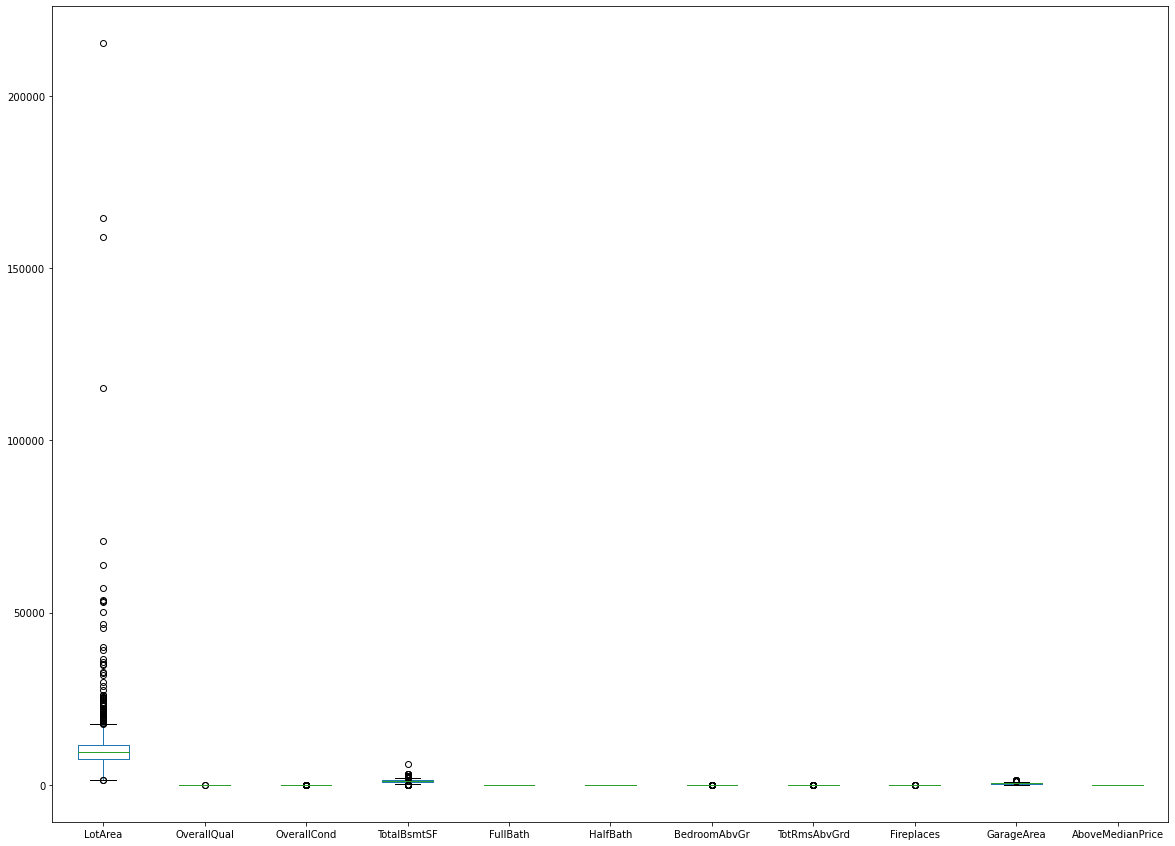

In [148]:
#Explorative Datenanalyse
"""hier geht es darum besonders zu untersuchen, wie die komplette Verteilung der 
   Daten aussieht. In diesem Fall wird einen Box-Plots der Zahlenwerte erstellt, um einen Überblick zu erhalten.
"""
variable=["LotArea", "OverallQual", "OverallCond", "TotalBsmtSF", "FullBath", "HalfBath", "BedroomAbvGr", "TotRmsAbvGrd", "Fireplaces", "GarageArea", "AboveMedianPrice"]
(houses[variable]).plot.box(figsize=(20, 15))

In [ ]:
    #Beschreibung
        """Es wird festgestellt, dass visuell nur die Variable „LotArea“ diejenige ist, die etwas mehr Informationen liefert.
        """

Text(0, 0.5, 'LotArea')

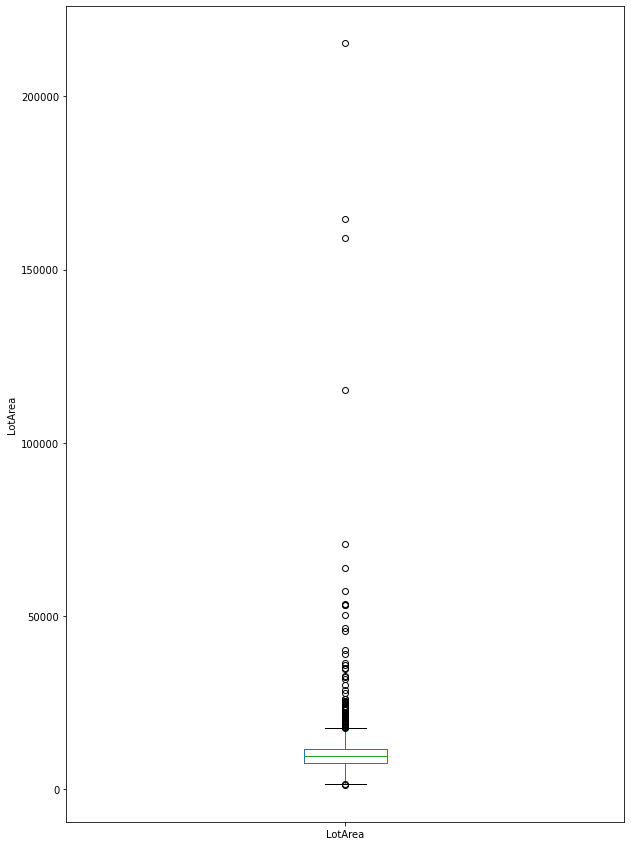

In [151]:
    #Betrachten wir jetzt das Attribut „LotArea“ genauer. Sein Boxplot sieht wie folgt aus:
    ax =(houses['LotArea']).plot.box(figsize=(10, 15))
    ax.set_ylabel('LotArea')

In [ ]:
    #Beschreibung
        """Anhand des Boxplots kann man visuell erkennen, dass der Median (fett gehaltene horizontale Linie) bei etwa 10000 liegt.
           die Variable LotArea auf einer Fläche zwischen 9 und 11000 konzentriert ist und es Ausreißer gibt (Datenpunkte außerhalb der Whisker, die in der Regel als Ausreißer angesehen werden). 
           Die vertikalen Linien am oberen und unteren Rand der Box werden als Whisker bezeichnet und zeigen den Bereich an, in dem sich die meisten Daten befinden.
        """

In [152]:
    #Hier wird angeschaut, inwieweit die einzelnen Attribute mit dem Attribut LotArea korrelieren.
    corr_matrix = houses.corr()

    corr_matrix["LotArea"].sort_values(ascending=False)

LotArea             1.000000
Fireplaces          0.271364
TotalBsmtSF         0.260833
TotRmsAbvGrd        0.190015
AboveMedianPrice    0.189180
GarageArea          0.180403
FullBath            0.126031
BedroomAbvGr        0.119690
OverallQual         0.105806
HalfBath            0.014259
OverallCond        -0.005636
Name: LotArea, dtype: float64

In [ ]:
    #Beschreibung
        """Insgesamt lässt sich feststellen, dass es fast keine lineare oder positive Korrelation zwischen der Variable „LotArea“ und dem Rest gibt. Die nächstliegende Korrelation ist die der Variable „Fireplaces“ mit (0,271364), die für die Vorhersage der Zielvariable unbedeutend ist. 
           Und es zeigt sich sogar, dass es eine negative Korrelation mit der Variable „OverallCond“ gibt.
        """

array([[<AxesSubplot:xlabel='LotArea', ylabel='LotArea'>,
        <AxesSubplot:xlabel='OverallQual', ylabel='LotArea'>,
        <AxesSubplot:xlabel='OverallCond', ylabel='LotArea'>,
        <AxesSubplot:xlabel='TotalBsmtSF', ylabel='LotArea'>,
        <AxesSubplot:xlabel='FullBath', ylabel='LotArea'>,
        <AxesSubplot:xlabel='HalfBath', ylabel='LotArea'>,
        <AxesSubplot:xlabel='BedroomAbvGr', ylabel='LotArea'>,
        <AxesSubplot:xlabel='TotRmsAbvGrd', ylabel='LotArea'>,
        <AxesSubplot:xlabel='Fireplaces', ylabel='LotArea'>,
        <AxesSubplot:xlabel='GarageArea', ylabel='LotArea'>,
        <AxesSubplot:xlabel='AboveMedianPrice', ylabel='LotArea'>],
       [<AxesSubplot:xlabel='LotArea', ylabel='OverallQual'>,
        <AxesSubplot:xlabel='OverallQual', ylabel='OverallQual'>,
        <AxesSubplot:xlabel='OverallCond', ylabel='OverallQual'>,
        <AxesSubplot:xlabel='TotalBsmtSF', ylabel='OverallQual'>,
        <AxesSubplot:xlabel='FullBath', ylabel='OverallQual'>,

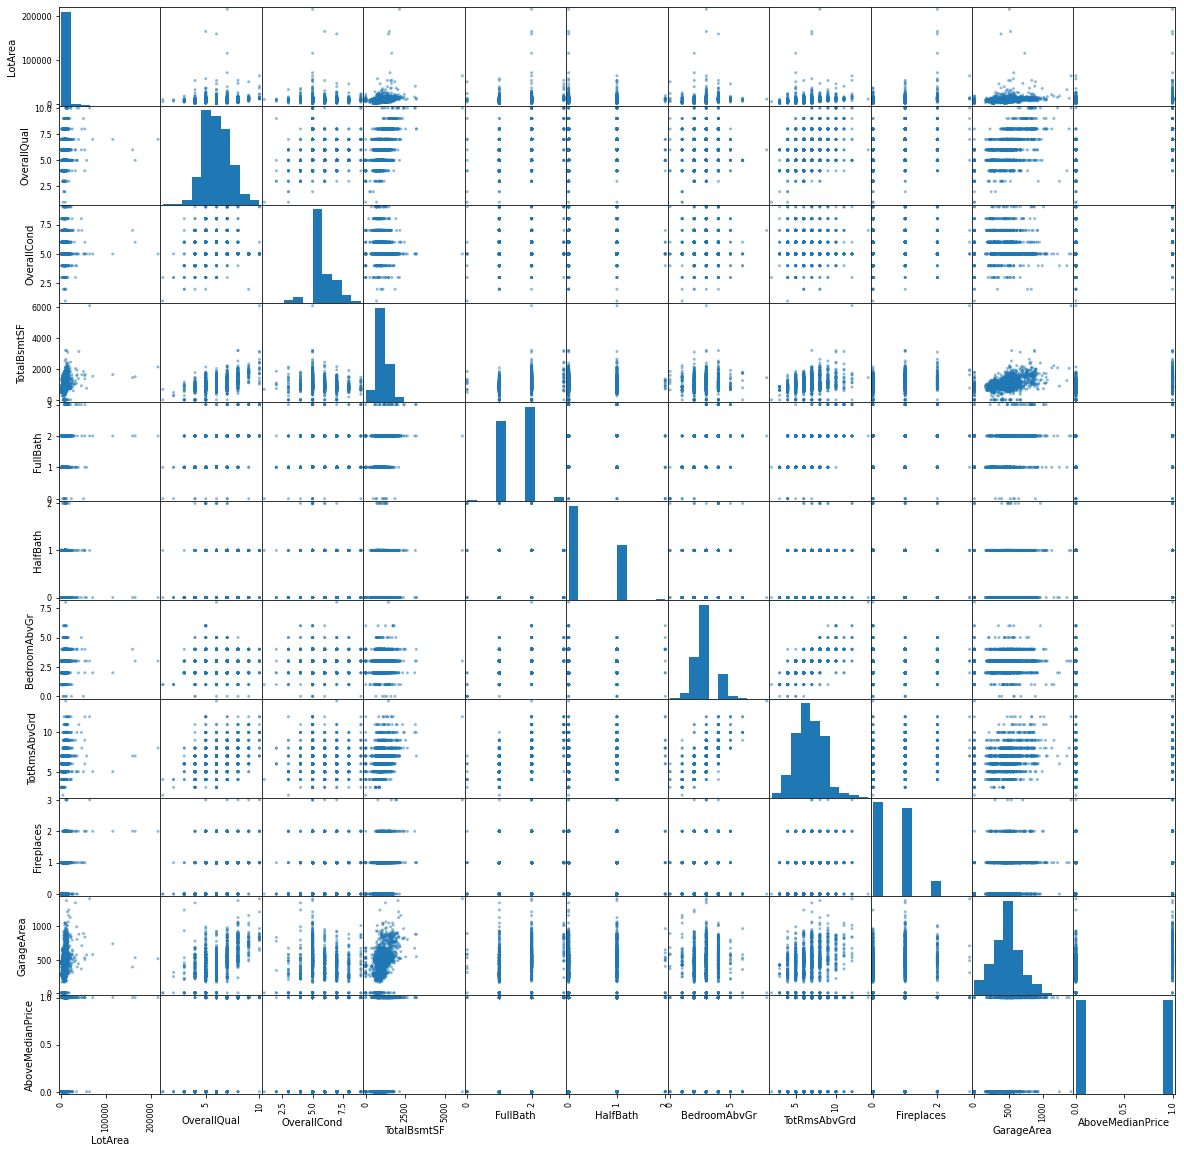

In [11]:
    #Visuelle Untersuchung
        """Wir wollen auch eine visuelle Korrelation erstellen, indem wir die Funktion scatter_matrix() des Pandas-Moduls verwenden, 
           die jedes numerische Attribut gegen jedes andere numerische Attribut plottet, plus ein Histogramm jedes numerischen Attributs.
        """
from pandas.plotting import scatter_matrix
attributes = ["LotArea", "OverallQual", "OverallCond", "TotalBsmtSF", "FullBath", "HalfBath", "BedroomAbvGr", "TotRmsAbvGrd", "Fireplaces", "GarageArea", "AboveMedianPrice"]
scatter_matrix(houses[attributes], figsize=(20, 20))

<AxesSubplot:xlabel='TotalBsmtSF', ylabel='GarageArea'>

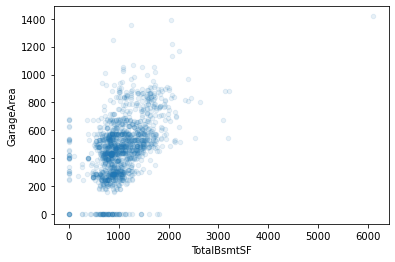

In [153]:
    #Beschreibung
        """Visuell fällt auf, dass es offenbar eine Korrelation zwischen der Variablen „TotalBsmtSF“ und der Variablen „GarageArea“ gibt.
           Das Histogramm jeder Variablen befindet sich am Treffpunkt mit der Diagonalen.
           Vergrößern wir also ihr Korrelationsstreudiagramm.
        """
        houses.plot(kind="scatter", x="TotalBsmtSF", y="GarageArea", alpha=0.1)

In [154]:
    #Beschreibung
        """Die Korrelation ist in der Tat sehr stark. Man kann den Aufwärtstrend deutlich erkennen, und die Punkte sind nicht zu weit auseinander.
           Wie sieht es numerisch aus?
        """
        corr_matrix = houses.corr()

        corr_matrix["GarageArea"].sort_values(ascending=False)

GarageArea          1.000000
OverallQual         0.562022
AboveMedianPrice    0.505068
TotalBsmtSF         0.486665
FullBath            0.405656
TotRmsAbvGrd        0.337822
Fireplaces          0.269141
LotArea             0.180403
HalfBath            0.163549
BedroomAbvGr        0.065253
OverallCond        -0.151521
Name: GarageArea, dtype: float64

In [ ]:
    #Beschreibung
    """Die Korrelation beträgt 0,486665. Das ist im Vergleich zur Variable „LotArea“ nicht schlecht."""

In [ ]:
Teilaufgabe 3b) Modellbildung und Evaluation
"""Nutzen Sie dann drei verschiedene Klassifizierer ihrer Wahl und vergleichen Sie deren
Performance, indem Sie die Daten in Trainings- und Testdaten aufteilen und für die Evaluation
der Testdaten jeweils eine Wahrheitstabelle (Confusion Matrix) erstellen. Kommentieren Sie
ihren Code und versuchen Sie zu begründen, warum die Performance je Klassifizierer
unterschiedlich ausfällt / ausfallen kann. """

In [155]:
#Aufteilung der Daten in Trainings- und Testdaten
import numpy as np

def split_train_test(data, test_ratio):
    shuffled_indices = np.random.permutation(len(data))
    test_set_size = int(len(data) * test_ratio)
    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]
    return data.iloc[train_indices], data.iloc[test_indices]

In [156]:
train_set, test_set = split_train_test(houses, 0.2)

In [157]:
len(train_set)

1168

In [158]:
len(test_set)

292

In [70]:
#Dadurch wird sichergestellt, dass der Testsatz über mehrere Durchläufe hinweg konsistent bleibt, auch wenn Sie den Datensatz aktualisieren.
from zlib import crc32

def test_set_check(identifier, test_ratio):
    return crc32(np.int64(identifier)) & 0xffffffff < test_ratio * 2**32

def split_train_test_by_id(data, test_ratio, id_column):
    ids = data[id_column]
    in_test_set = ids.apply(lambda id_: test_set_check(id_, test_ratio))
    return data.loc[~in_test_set], data.loc[in_test_set]

houses_with_id = houses.reset_index() #eine 'Index'-Spalte hinzufügen
train_set, test_set = split_train_test_by_id(houses_with_id, 0.2, "index")

In [161]:
#Datenvorbereitung für Algorithmen des maschinellen Lernens.
    #Trennen wir die Prädiktoren und die Labels.
    houses = train_set.drop("GarageArea", axis=1)  #drop() erstellt eine Kopie der Daten.
    houses_labels = train_set["GarageArea"].copy()

In [125]:
#Auswahl und Training des Modells
import sklearn

from sklearn import linear_model
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(houses, houses_labels) #fit()-Methode für die Schätzung

LinearRegression()

In [162]:
#Probieren wir es nun mit der Trainingsmenge aus:
print("Predictions:", lin_reg.predict(houses))

Predictions: [-0.01908314  0.63825624 -0.01093365 ... -0.01550156  0.41471939
  0.66676498]


In [163]:
print("Labels:", list(houses_labels))

Labels: [294, 380, 0, 240, 308, 552, 400, 240, 576, 474, 240, 484, 478, 486, 528, 390, 450, 720, 440, 616, 200, 968, 225, 393, 555, 528, 567, 400, 644, 271, 288, 0, 612, 490, 576, 572, 505, 280, 528, 354, 264, 784, 540, 461, 552, 0, 0, 480, 431, 720, 0, 462, 660, 812, 874, 480, 619, 364, 880, 694, 482, 403, 776, 301, 300, 0, 663, 839, 551, 288, 647, 467, 336, 437, 484, 280, 286, 301, 240, 460, 572, 403, 457, 410, 360, 546, 264, 480, 484, 1356, 413, 484, 282, 471, 756, 360, 610, 440, 208, 336, 440, 774, 281, 858, 560, 164, 521, 660, 400, 711, 0, 504, 264, 0, 442, 576, 624, 626, 564, 606, 0, 856, 308, 1134, 288, 836, 757, 384, 434, 481, 626, 539, 833, 0, 484, 400, 400, 615, 360, 750, 611, 308, 220, 562, 528, 820, 530, 525, 614, 788, 550, 520, 462, 300, 409, 678, 260, 460, 288, 240, 672, 304, 280, 508, 656, 736, 577, 520, 275, 352, 574, 472, 528, 813, 534, 457, 350, 702, 0, 625, 280, 528, 431, 701, 504, 312, 384, 542, 338, 336, 480, 0, 834, 515, 418, 539, 576, 1052, 608, 528, 451, 765, 51

In [164]:
#Measure the regression model
from sklearn.metrics import mean_squared_error
houses_predictions = lin_reg.predict(houses)
lin_mse = mean_squared_error(houses_labels, houses_predictions)
lin_rmse = np.sqrt(lin_mse)
lin_rmse

520.4693402974899

In [165]:
#Erstellung einer Wahrheitstabelle oder Confusion Matrix
    #Stochatic Gradient Descent (SGD) Klassifikator, unter Verwendung der SGDClassifier-Klasse von Scikit-Learn.
        #Wir erstellen einen SGDClassifier und trainieren ihn mit dem gesamten Trainingsset:
        from sklearn.linear_model import SGDClassifier
        
        sgd_clf = SGDClassifier(random_state=42)
        sgd_clf.fit(houses, houses_labels)
        
        sgd_clf.predict([houses])
     
        #Performance Messung

ValueError: Found array with dim 3. Estimator expected <= 2.